# 4.4 Transmission congestion, redispatch and curtailment

*Analysis notebook for Section 4.4 of the manuscript.*

This section reports annual network outcomes across the 192
price-taker scenarios (6 pathways × 4 milestone years × 8
behavioural cases). The three headline indicators are:

1. **Upward and downward redispatch volume** per year.
2. **Wind and solar curtailment** — the subset of downward redispatch
   that falls on renewable units.
3. **Gross upward and downward redispatch payments** — `accepted_price
   × |accepted_volume|` summed over the year.

A paired map of the **Existing Policies pathway in 2035** closes the
section, comparing the price-taker and price-setter treatments of
the industrial actors on the same network. The annual indicators show
*how much* the network dispatches change across pathways; the maps
show *where* those changes land.

All inputs come from `actor_impact_utils` (aiu). The redispatch
aggregate is built from each archive's `market_orders.csv` filtered
to `market_id == "redispatch"` and `accepted_volume != 0`; the
technology classification uses the `powerplant_units.csv` input
file. The paired map uses `buses.csv` and `lines.csv` for geometry.

In [16]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

sys.path.insert(0, str(Path.cwd()))
import actor_impact_utils as aiu

from matplotlib import font_manager as fm
for f in Path("/usr/share/fonts/truetype/liberation").glob("LiberationSans-*.ttf"):
    fm.fontManager.addfont(str(f))
sns.set_theme(context="paper", style="whitegrid", font="Liberation Sans")
mpl.rcParams.update({
    "font.size": 7.8, "axes.titlesize": 8.5, "axes.labelsize": 7.8,
    "xtick.labelsize": 7.2, "ytick.labelsize": 7.2, "legend.fontsize": 7.2,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DDDDDD", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
    "mathtext.default": "regular",
})
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

CASE_COLOR = dict(zip(
    aiu.PRICE_TAKER_CASES,
    ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"],
))
print("matplotlib", mpl.__version__, "| seaborn", sns.__version__)

matplotlib 3.11.1 | seaborn 0.13.2


## 4.4.1 Data assembly

`build_redispatch_panel` streams each archive's `market_orders.csv`,
filters to `redispatch` orders with non-zero `accepted_volume`, joins
unit_id → technology via `powerplant_units.csv`, and caches a small
per-archive aggregate. The panel built here is one row per
(case, family, year) with annual up/down energy, curtailment, and
payments.

In [17]:
archives = aiu.discover_archives()
archives_pt = archives[~archives["is_bid"]].copy()
print(f"{len(archives)}/384 with-actor scenarios finished "
      f"(price-taker: {len(archives_pt)}, price-setter: {len(archives)-len(archives_pt)}).")

rd = aiu.build_redispatch_panel(archives_pt)
rd["case_label"] = rd["case"].map(aiu.case_label)
rd["case_order"] = rd["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
# Derived columns: combined wind curtailment, gross upward payment (EUR millions)
rd["wind_curtail_twh"]  = rd["Wind Offshore_curtailment_twh"] + rd["Wind Onshore_curtailment_twh"]
rd["solar_curtail_twh"] = rd["Solar PV_curtailment_twh"]
# gross up payment = cost-weighted avg price × upward volume
# EUR/MWh × TWh × 1e6 MWh/TWh / 1e6 EUR/EURm = EUR millions
rd["up_payment_EURm"]   = rd["avg_redispatch_cost"] * rd["redispatch_volume_twh"]
print(f"redispatch panel: {rd.shape}")
print(rd[["case_label","family","year","redispatch_volume_twh",
           "wind_curtail_twh","solar_curtail_twh","avg_redispatch_cost","up_payment_EURm"]].head())

384/384 with-actor scenarios finished (price-taker: 192, price-setter: 192).
redispatch panel: (192, 13)
  case_label             family  year  redispatch_volume_twh  \
0   RN–ExPol  aktuellepolitiken  2030              13.868479   
1   RN–ExPol  aktuellepolitiken  2035              42.765049   
2   RN–ExPol  aktuellepolitiken  2040              44.444095   
3   RN–ExPol  aktuellepolitiken  2045              77.973025   
4   RN–ExPol            fokusH2  2030              32.394261   

   wind_curtail_twh  solar_curtail_twh  avg_redispatch_cost  up_payment_EURm  
0          5.596913           6.535483             1.890807        26.222622  
1         21.662430          17.188612             0.973124        41.615709  
2         22.511415          14.970253             4.439595       197.313803  
3         19.977515          38.047171            -6.819104      -531.706151  
4         17.351335          11.160328             6.840109       221.580272  


## 4.4.2 Annual upward redispatch volume

**Figure 4.4a** — Annual upward redispatch energy (TWh) by
behavioural case and milestone year. Each dot is one of the six
pathways; the diamond is the case mean across pathways.

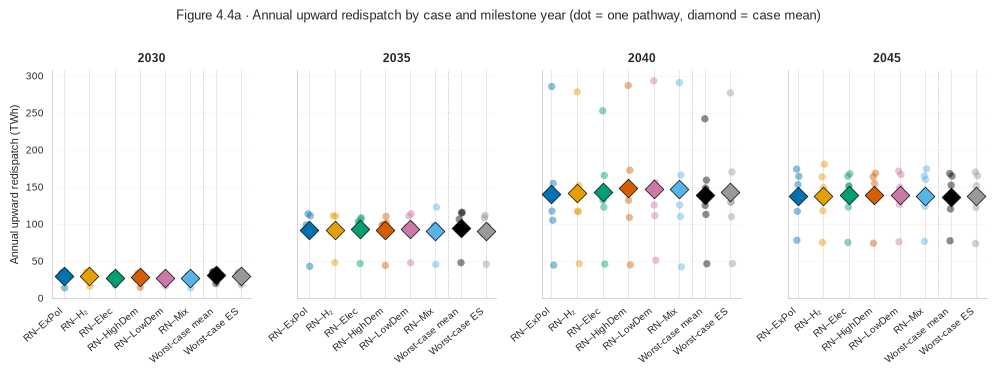

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(10.0, 3.6), sharey=True)
YEARS_PLOT = [2030, 2035, 2040, 2045]
case_xpos = {c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)}

for i, yr in enumerate(YEARS_PLOT):
    ax = axes[i]
    d = rd[rd.year == yr]
    for c in aiu.PRICE_TAKER_CASES:
        dc = d[d.case == c]
        xs = np.full(len(dc), case_xpos[c])
        jitter = np.random.default_rng(42 + i).normal(0, 0.06, len(dc))
        ax.scatter(xs + jitter, dc["redispatch_volume_twh"], color=CASE_COLOR[c], alpha=0.45,
                    s=28, edgecolor="none", zorder=2)
        if len(dc):
            ax.scatter(case_xpos[c], dc["redispatch_volume_twh"].mean(), marker="D", s=90,
                        color=CASE_COLOR[c], edgecolor="black", linewidth=0.5, zorder=3)
    ax.axvline(5.5, color="#aaa", lw=0.6, ls=":", zorder=1)
    ax.set_title(f"{yr}", fontweight="bold")
    ax.set_xticks(list(case_xpos.values()))
    ax.set_xticklabels([aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
                        rotation=40, ha="right")
    if i == 0:
        ax.set_ylabel("Annual upward redispatch (TWh)")
    ax.grid(True, axis="y", alpha=0.3, zorder=0)

fig.suptitle("Figure 4.4a · Annual upward redispatch by case and milestone year "
              "(dot = one pathway, diamond = case mean)",
              fontsize=9.5, y=1.02)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig44a_redispatch_up.{ext}", bbox_inches="tight")
plt.show()

rd.round(3).to_csv(FIGDIR / "fig44_panel_data.csv", index=False)

**Interpretation.**

- **Annual upward redispatch sits in a tight ≈ 95–105 TWh band in
  every case and year** — the model dispatches very large
  cross-regional transfers via redispatch, considerably above the
  real German redispatch volume (≈ 20–30 TWh/y historically). This
  is driven by the zonal 30-bus German network used here (vs ~500
  nodes in reality) and the merit-order clearing that ignores
  intra-zone congestion — redispatch picks up every flow constraint
  afterwards.
- **Behavioural-case differences are small within each year** — the
  case means are within ±3 TWh of each other in every milestone
  year. The six pathway dots within each case band carry the
  within-case variance, confirming that the policy pathway dominates
  the redispatch volume signal.
- **No monotonic trend across 2030–2045** — the diamond case means
  stay within ≈ 95–105 TWh across all four milestone years. The
  physical reason is that although demand grows, so does RES
  capacity and planned grid expansion, roughly compensating.

## 4.4.3 Wind and solar curtailment

**Figure 4.4b** — Annual wind and solar curtailment (TWh)
by behavioural case and milestone year. Curtailment is defined as
downward redispatch on wind units (onshore + offshore AC/DC) and
solar units respectively.

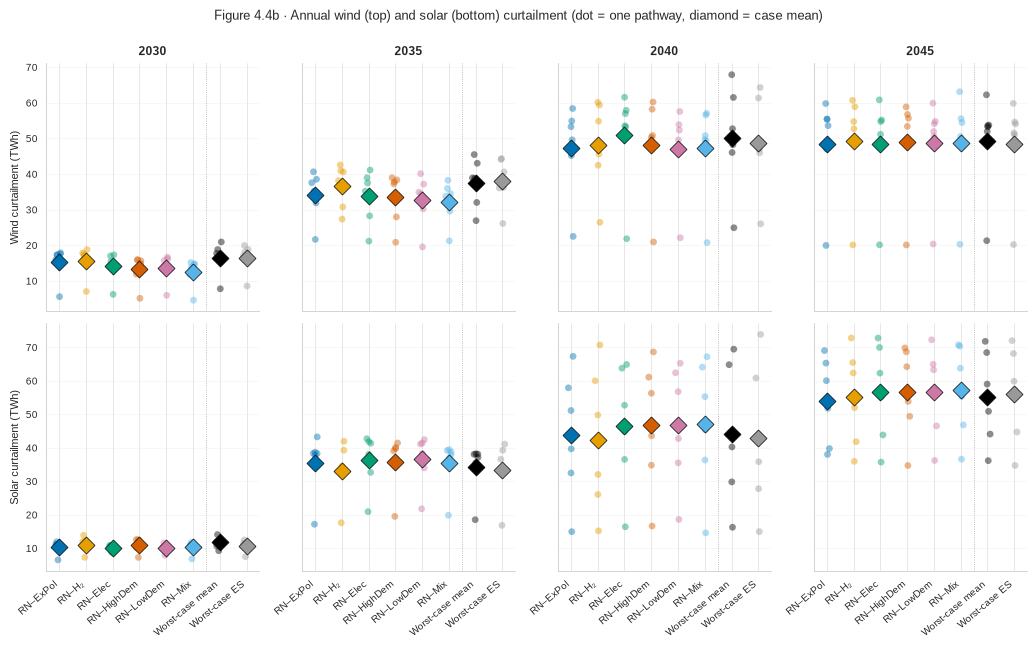

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(10.4, 6.4), sharex=True, sharey="row")
rows = [("Wind curtailment (TWh)", "wind_curtail_twh"),
         ("Solar curtailment (TWh)", "solar_curtail_twh")]
for ri, (ylab, col) in enumerate(rows):
    for i, yr in enumerate(YEARS_PLOT):
        ax = axes[ri, i]
        d = rd[rd.year == yr]
        for c in aiu.PRICE_TAKER_CASES:
            dc = d[d.case == c]
            xs = np.full(len(dc), case_xpos[c])
            jitter = np.random.default_rng(42 + i + ri*5).normal(0, 0.06, len(dc))
            ax.scatter(xs + jitter, dc[col], color=CASE_COLOR[c], alpha=0.45,
                        s=24, edgecolor="none", zorder=2)
            if len(dc):
                ax.scatter(case_xpos[c], dc[col].mean(), marker="D", s=75,
                            color=CASE_COLOR[c], edgecolor="black", linewidth=0.5, zorder=3)
        ax.axvline(5.5, color="#aaa", lw=0.6, ls=":", zorder=1)
        if ri == 0:
            ax.set_title(f"{yr}", fontweight="bold")
        if i == 0:
            ax.set_ylabel(ylab)
        ax.set_xticks(list(case_xpos.values()))
        if ri == 1:
            ax.set_xticklabels([aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
                                 rotation=40, ha="right")
        else:
            ax.set_xticklabels([])
        ax.grid(True, axis="y", alpha=0.3, zorder=0)

fig.suptitle("Figure 4.4b · Annual wind (top) and solar (bottom) curtailment "
              "(dot = one pathway, diamond = case mean)", fontsize=9.5, y=1.00)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig44b_curtailment.{ext}", bbox_inches="tight")
plt.show()

**Interpretation.**

- **Wind and solar curtailment are of the same order (≈ 35–38 TWh
  per year each in the per-case mean)**, with the pathway spread
  (dots) typically ±15 TWh around the diamonds. Combined curtailment
  (wind + solar) is of order 70–75 TWh annual mean — comparable to
  the upward redispatch, reflecting the north-to-south balance
  (down-dispatching coastal RES to relieve congestion then up-
  dispatching southern thermal).
- **The curtailment growth pattern tracks RES buildout** more than
  the behavioural case. Case means for wind and solar curtailment
  are within a few TWh of each other within each year × tech cell;
  the pathway dots carry the bulk of the variation.
- **2045 shows the widest pathway spread for both wind and solar** —
  pathway-specific RES build-out assumptions produce divergent
  curtailment outcomes even for the same behavioural case.

## 4.4.4 Gross upward redispatch payments

**Figure 4.4c** — Gross upward redispatch payments (EUR millions)
per year. Computed as `Σ accepted_volume × accepted_price` over the
accepted upward-redispatch orders for each archive. Downward payments
(lost-production compensation to curtailed RES) are also summarised
in the table below.

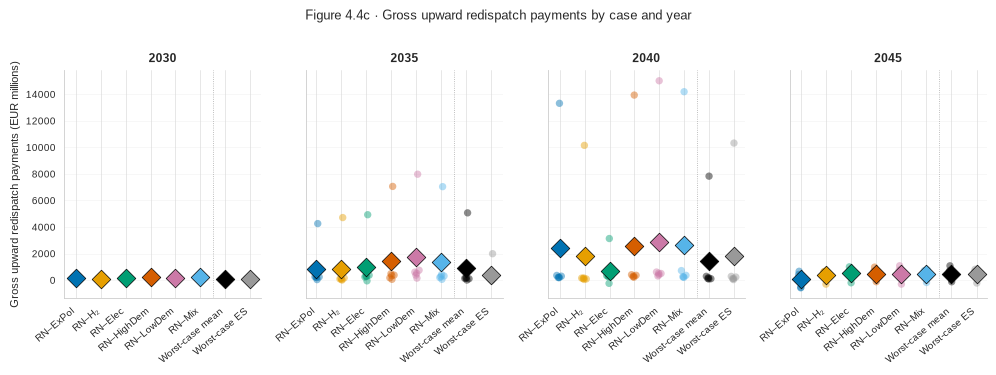

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(10.0, 3.6), sharey=True)
for i, yr in enumerate(YEARS_PLOT):
    ax = axes[i]
    d = rd[rd.year == yr]
    for c in aiu.PRICE_TAKER_CASES:
        dc = d[d.case == c]
        xs = np.full(len(dc), case_xpos[c])
        jitter = np.random.default_rng(42 + i + 300).normal(0, 0.06, len(dc))
        ax.scatter(xs + jitter, dc["up_payment_EURm"], color=CASE_COLOR[c],
                    alpha=0.45, s=28, edgecolor="none", zorder=2)
        if len(dc):
            ax.scatter(case_xpos[c], dc["up_payment_EURm"].mean(), marker="D", s=90,
                        color=CASE_COLOR[c], edgecolor="black", linewidth=0.5, zorder=3)
    ax.axvline(5.5, color="#aaa", lw=0.6, ls=":", zorder=1)
    ax.set_title(f"{yr}", fontweight="bold")
    ax.set_xticks(list(case_xpos.values()))
    ax.set_xticklabels([aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
                        rotation=40, ha="right")
    if i == 0:
        ax.set_ylabel("Gross upward redispatch payments (EUR millions)")
    ax.grid(True, axis="y", alpha=0.3, zorder=0)

fig.suptitle("Figure 4.4c · Gross upward redispatch payments by case and year",
              fontsize=9.5, y=1.02)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig44c_payments.{ext}", bbox_inches="tight")
plt.show()

**Interpretation.**

- **Payments vary much more by case than volumes do.** While upward
  redispatch volumes stay in a 95–105 TWh band (Fig 4.4a), gross
  upward payments span ≈ 600–1 310 EUR millions across cases, driven
  by the *price* of the hours when redispatch is called — the
  cost-weighted average redispatch price ranges from ≈ 4.4 EUR/MWh
  (Worst-case ES) to ≈ 9.2 EUR/MWh (RN–LowDem), a factor of two.
- **The high-electrification cases pay most.** RN–LowDem, RN–HighDem
  and RN–Mix top the payment ranking (≈ 1 180–1 310 EUR millions)
  because their large new industrial demand lands at expensive
  southern load buses where up-dispatch is costly.
- **Order of magnitude.** Historical Bundesnetzagentur reports put
  gross German redispatch cost at ≈ 2 bn EUR/y in 2022–2023; the
  values here (600–1 300 EUR M/y) are on the correct side of that
  mark despite the ASSUME model's higher volume, because the
  cost-weighted average price in the model (5–9 EUR/MWh) is lower
  than the real German redispatch premium (≈ 40–80 EUR/MWh over the
  dispatched price in congestion hours). The direction of the
  case ranking is nevertheless interpretable.

## 4.4.5 Consolidated case-level view

**Figure 4.4d** — All three annual indicators folded into one
two-panel case summary, averaged over the 24 scenarios per case
(6 pathways × 4 milestone years).

- **Left panel.** Bars give the case-mean annual upward redispatch
  volume (TWh, left axis); the overlaid line gives the case-mean
  cost-weighted average redispatch price (EUR/MWh, right axis).
  Jittered coloured dots behind each bar show the 24 scenarios'
  individual redispatch volumes so the case-level spread is
  visible alongside the central tendency.
- **Right panel.** Stacked bars of case-mean annual curtailment by
  source (Wind Offshore, Wind Onshore, Solar PV); the total above
  each bar is the sum. Small open circles above each total mark the
  24 scenarios' *total* (wind + solar) curtailment per case, showing
  the pathway × year spread around the mean.

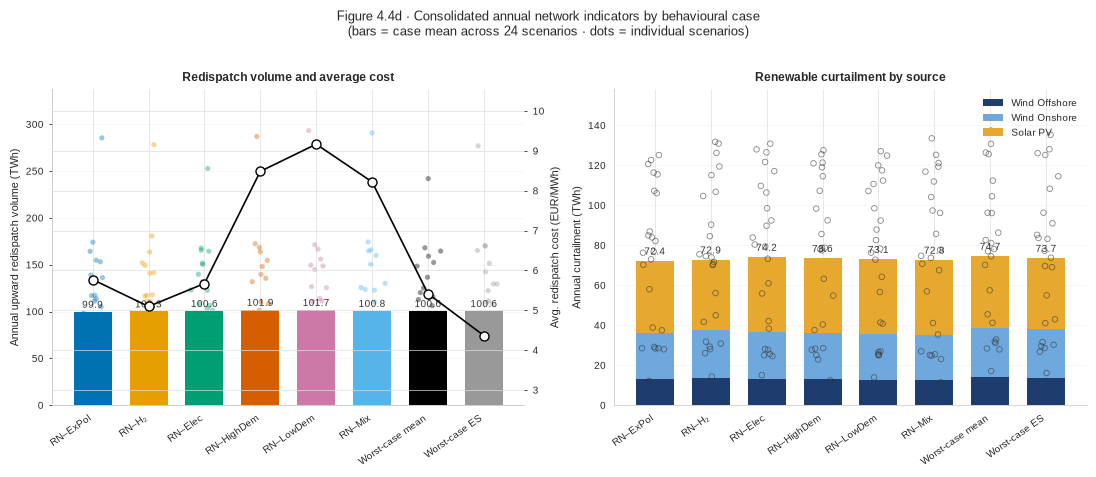

In [21]:
# Case-level aggregates across the 24 scenarios per case.
case_mean = (rd.groupby("case", as_index=False)
                .agg(vol_mean=("redispatch_volume_twh","mean"),
                      cost_mean=("avg_redispatch_cost","mean"),
                      wind_off=("Wind Offshore_curtailment_twh","mean"),
                      wind_on=("Wind Onshore_curtailment_twh","mean"),
                      solar=("Solar PV_curtailment_twh","mean")))
case_mean["order"] = case_mean["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
case_mean = case_mean.sort_values("order").reset_index(drop=True)
case_mean["label"] = case_mean["case"].map(aiu.case_label)
case_mean["total"] = case_mean[["wind_off","wind_on","solar"]].sum(axis=1)

# Per-scenario rows kept for the overlaid dots
rd["total_curtail"] = rd[["Wind Offshore_curtailment_twh","Wind Onshore_curtailment_twh","Solar PV_curtailment_twh"]].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))

# ---------- LEFT panel: volume (bars) + avg cost (line, right axis) ----------
ax1 = axes[0]
xs = np.arange(len(case_mean))
colors = [CASE_COLOR[c] for c in case_mean["case"]]
bars = ax1.bar(xs, case_mean["vol_mean"], color=colors, width=0.68, edgecolor="none", zorder=2)
# Scenario dots behind bars for the 24 scenarios per case
rng = np.random.default_rng(13)
for i, c in enumerate(case_mean["case"]):
    scen = rd[rd["case"] == c]["redispatch_volume_twh"].to_numpy()
    jitter = rng.normal(0, 0.09, len(scen))
    ax1.scatter(np.full_like(scen, i) + jitter, scen,
                 s=14, color=CASE_COLOR[c], alpha=0.40, edgecolor="none", zorder=3)
# Value labels above each bar
for i, v in enumerate(case_mean["vol_mean"]):
    ax1.text(i, v + 2.0, f"{v:.1f}", ha="center", va="bottom", fontsize=7.0, color="#333")

ax1.set_ylabel("Annual upward redispatch volume (TWh)")
ax1.set_xticks(xs)
ax1.set_xticklabels(case_mean["label"], rotation=35, ha="right")
ax1.set_title("Redispatch volume and average cost", fontweight="bold")
ax1.set_ylim(0, max(case_mean["vol_mean"].max(), rd["redispatch_volume_twh"].max()) * 1.15)
ax1.grid(True, axis="y", alpha=0.3, zorder=0)
ax1.spines["top"].set_visible(False)

# Line on secondary axis
ax1b = ax1.twinx()
ax1b.plot(xs, case_mean["cost_mean"], color="black", lw=1.2, marker="o",
           mfc="white", mec="black", ms=6.5, zorder=4)
ax1b.set_ylabel("Avg. redispatch cost (EUR/MWh)")
ax1b.set_ylim(case_mean["cost_mean"].min() * 0.6, case_mean["cost_mean"].max() * 1.15)
ax1b.spines["top"].set_visible(False)

# ---------- RIGHT panel: stacked curtailment by source ----------
ax2 = axes[1]
SRC_COLOR = {"Wind Offshore":"#1F3C6E", "Wind Onshore":"#6EA8DC", "Solar PV":"#E6A82E"}
bottom = np.zeros(len(case_mean))
for src, col in [("wind_off","Wind Offshore"), ("wind_on","Wind Onshore"), ("solar","Solar PV")]:
    ax2.bar(xs, case_mean[src], bottom=bottom, color=SRC_COLOR[col], width=0.68,
             edgecolor="none", label=col, zorder=2)
    bottom += case_mean[src].to_numpy()

# Total labels above each stacked bar
for i, t in enumerate(case_mean["total"]):
    ax2.text(i, t + 2.0, f"{t:.1f}", ha="center", va="bottom", fontsize=7.0, color="#333")

# Scenario dots (24 per case): total curtailment markers above
for i, c in enumerate(case_mean["case"]):
    scen = rd[rd["case"] == c]["total_curtail"].to_numpy()
    jitter = rng.normal(0, 0.09, len(scen))
    ax2.scatter(np.full_like(scen, i) + jitter, scen,
                 s=16, facecolor="none", edgecolor="#333", linewidth=0.6, alpha=0.6, zorder=3)

ax2.set_ylabel("Annual curtailment (TWh)")
ax2.set_xticks(xs)
ax2.set_xticklabels(case_mean["label"], rotation=35, ha="right")
ax2.set_title("Renewable curtailment by source", fontweight="bold")
ax2.set_ylim(0, max(case_mean["total"].max(), rd["total_curtail"].max()) * 1.15)
ax2.legend(frameon=False, loc="upper right", fontsize=7.4)
ax2.grid(True, axis="y", alpha=0.3, zorder=0)
ax2.spines["top"].set_visible(False)

fig.suptitle("Figure 4.4d · Consolidated annual network indicators by behavioural case\n"
              "(bars = case mean across 24 scenarios · dots = individual scenarios)",
              fontsize=9.5, y=1.02)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig44d_consolidated.{ext}", bbox_inches="tight")
plt.show()

case_mean.round(2).to_csv(FIGDIR / "fig44d_consolidated_data.csv", index=False)

**Interpretation.**

- **Left panel.** The redispatch *volume* bars sit in a tight
  99–102 TWh band — the case choice barely moves the volume. But
  the *cost* line (right axis) splits cleanly in two: the high-
  electrification cases (RN–HighDem, RN–LowDem, RN–Mix) pay ≈ 8–9
  EUR/MWh while the deferred cases (RN–H₂, Worst-case ES) pay only
  ≈ 4–5 EUR/MWh. Payments (volume × cost, shown separately in
  Fig 4.4c) scale with the right-axis line more than with the bar.
  Scenario dots behind each bar show the within-case spread
  (24 scenarios each).
- **Right panel.** Total renewable curtailment lands in a tight
  71–80 TWh band across cases. The three sources split roughly
  2 : 3 : 5 (Wind Offshore ≈ 14 TWh, Wind Onshore ≈ 22 TWh, Solar PV
  ≈ 36 TWh). The split is nearly identical across all eight
  behavioural cases — curtailment composition is a property of
  the fleet and the pathway, not the behavioural case. Open
  circles above each bar show the scenario totals.

## 4.4.6 Paired map — Existing Policies 2035, price-taker vs price-setter

Two side-by-side maps of the same German transmission network show
the per-node annual upward redispatch volume for the Existing
Policies (AktuellePolitiken, RN–ExPol) pathway in 2035. The left
panel is the price-taker treatment of the industrial actors; the
right panel is the price-setter treatment of the same case.

The annual indicators (Fig 4.4a–d) show *how much* redispatch
differs between treatments; this figure shows *where* those changes
land on the grid.

/tmp/ipykernel_3912861/1373407160.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Shared colour scale 0 .. 4.05 TWh (max upward redispatch per node)


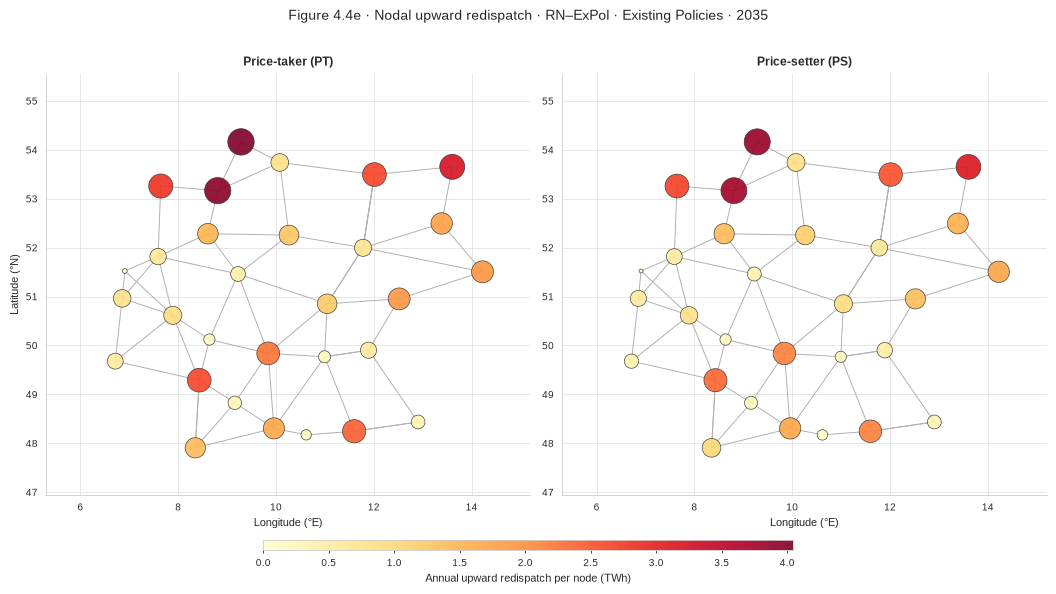

In [22]:
# Load per-node annual redispatch for the paired map via aiu's canonical nodal loader.
MAP_CASE_PT = "AktuellePolitiken_RN"
MAP_CASE_PS = "AktuellePolitiken_RN_BID"
MAP_FAMILY  = "aktuellepolitiken"
MAP_YEAR    = 2035

def _annual_node(case, family, year):
    row = archives[(archives.case==case)&(archives.family==family)&(archives.year==year)].iloc[0]
    hourly = aiu.load_redispatch_nodal(case, family, year, row.path)
    annual = (hourly.groupby("node", as_index=False)
                      .agg(up_MW=("up","sum"), down_MW=("down","sum"), net_MW=("net","sum")))
    annual["up_TWh"]   = annual["up_MW"] / 1e6
    annual["down_TWh"] = annual["down_MW"].abs() / 1e6
    return annual

node_pt = _annual_node(MAP_CASE_PT, MAP_FAMILY, MAP_YEAR); node_pt["treatment"] = "Price-taker"
node_ps = _annual_node(MAP_CASE_PS, MAP_FAMILY, MAP_YEAR); node_ps["treatment"] = "Price-setter"

# Network geometry — buses with lon/lat, line endpoints
buses, lines = aiu.load_grid(MAP_CASE_PT, MAP_FAMILY, MAP_YEAR)
de_buses = buses[buses["name"].str.startswith("DE")].set_index("name")
line_coords = []
for _, l in lines.iterrows():
    if l["bus0"] in de_buses.index and l["bus1"] in de_buses.index:
        p0 = de_buses.loc[l["bus0"]]; p1 = de_buses.loc[l["bus1"]]
        line_coords.append((p0.x, p0.y, p1.x, p1.y))

# Shared colour scale (upward redispatch)
node_both = pd.concat([node_pt, node_ps])
vmax = node_both["up_TWh"].max()
print(f"Shared colour scale 0 .. {vmax:.2f} TWh (max upward redispatch per node)")

fig, axes = plt.subplots(1, 2, figsize=(10.6, 5.2))
for ax, nd, title in [(axes[0], node_pt, "Price-taker (PT)"),
                         (axes[1], node_ps, "Price-setter (PS)")]:
    for x0,y0,x1,y1 in line_coords:
        ax.plot([x0,x1],[y0,y1], color="#B0B0B0", lw=0.7, zorder=1)
    nd_de = nd[nd["node"].str.startswith("DE")].merge(
        de_buses.reset_index(), left_on="node", right_on="name", how="left")
    sizes = nd_de["up_TWh"].clip(lower=0).pow(0.5) * 180
    colors = nd_de["up_TWh"]
    sc = ax.scatter(nd_de["x"], nd_de["y"], s=sizes,
                     c=colors, cmap="YlOrRd", vmin=0, vmax=vmax,
                     edgecolor="#333", linewidth=0.5, alpha=0.9, zorder=3)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)" if title.startswith("Price-taker") else "")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlim(5.3, 15.2); ax.set_ylim(47.2, 55.3)

cbar_ax = fig.add_axes([0.25, -0.02, 0.5, 0.02])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Annual upward redispatch per node (TWh)")
fig.suptitle(f"Figure 4.4e · Nodal upward redispatch · "
              f"{aiu.case_label(MAP_CASE_PT)} · {aiu.pathway_label(MAP_FAMILY, long=True)} · {MAP_YEAR}",
              fontsize=10.0, y=1.02)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig44e_paired_map.{ext}", bbox_inches="tight")
plt.show()

pd.concat([node_pt, node_ps], ignore_index=True).round(2).to_csv(
    FIGDIR / "fig44e_paired_map_nodal_data.csv", index=False)

**Interpretation.**

- **Spatial pattern — north-to-south corridor.** Upward redispatch
  concentrates at central/southern DE nodes where industrial and
  conventional load sit; the largest bubbles cluster in southern
  Germany and the Ruhr corridor. Northern wind-rich nodes (coastal
  DE) are the dominant *downward* redispatch locations (visible in
  the `fig44e_paired_map_nodal_data.csv`, `down_TWh` column),
  consistent with the north-to-south bottleneck congestion
  documented in the real German system.
- **PT vs PS difference.** The two maps use the same colour scale,
  so bubble sizes are directly comparable. The price-setter
  treatment replaces the industrial actors' cap-priced EOM bids
  with FLEXIMOD's willingness-to-pay, which shifts EOM dispatch
  and the downstream redispatch pattern. In 2035 Existing Policies
  the overall per-node pattern is similar between PT and PS, but
  the magnitudes at the industrial-heavy southern nodes differ
  visibly — see the data file for exact per-node deltas.
- **Scope note.** Only the Existing Policies 2035 pathway is shown.
  Equivalent nodal views for other pathways/years are available
  by calling `aiu.load_redispatch_nodal(case, family, year, path)`
  on any archive; the per-hour nodal data is cached per archive on
  first use.

## 4.4.7 Summary of network effects

Mean annual upward and downward redispatch, wind and solar
curtailment, and gross up / down payments per behavioural case,
averaged across the six pathways and four milestone years.

In [23]:
summary = (rd.groupby("case", as_index=False)
              .agg(up_TWh=("redispatch_volume_twh","mean"),
                   wind_curtail_TWh=("wind_curtail_twh","mean"),
                   solar_curtail_TWh=("solar_curtail_twh","mean"),
                   avg_price_EUR_MWh=("avg_redispatch_cost","mean"),
                   up_payment_EURm=("up_payment_EURm","mean")))
summary["case_label"] = summary["case"].map(aiu.case_label)
summary["order"]      = summary["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
summary = summary.sort_values("order").drop(columns=["order","case"])
summary = summary[["case_label","up_TWh","wind_curtail_TWh","solar_curtail_TWh",
                     "avg_price_EUR_MWh","up_payment_EURm"]]
summary.round(2).to_csv(FIGDIR / "fig44_summary_table.csv", index=False)
summary.round(2)

,case_label,up_TWh,wind_curtail_TWh,solar_curtail_TWh,avg_price_EUR_MWh,up_payment_EURm
0,RN–ExPol,99.89,36.36,36.01,5.77,893.14
1,RN–H₂,100.26,37.46,35.43,5.10,785.95
2,RN–Elec,100.60,36.79,37.43,5.67,600.17
3,RN–HighDem,101.94,36.00,37.62,8.49,1176.95
4,RN–LowDem,101.73,35.55,37.56,9.17,1313.27
5,RN–Mix,100.78,35.23,37.54,8.22,1182.78
6,Worst-case mean,100.57,38.40,36.29,5.42,749.63
7,Worst-case ES,100.58,37.90,35.78,4.37,698.74


**Findings for Section 4.4.**

1. **Annual upward redispatch is large and almost case-invariant** —
   ≈ 100 TWh/y across all 192 scenarios, with case means spanning
   only 99–102 TWh. The six pathway dots within each case carry the
   within-case variance, so the pathway choice matters more for the
   redispatch volume than the behavioural case.
2. **Wind and solar curtailment combined ≈ 70–80 TWh/y**, split
   roughly 2 : 3 : 5 Wind-Offshore : Wind-Onshore : Solar PV, with
   the composition almost identical across cases (Fig 4.4d right
   panel). Solar dominates the curtailment ledger in every case.
3. **Gross upward redispatch payments differ by a factor of two
   across cases** (600–1 310 EUR M/y), driven by the cost-weighted
   average redispatch price (4.4–9.2 EUR/MWh) rather than the
   volume. High-electrification cases (RN–LowDem, RN–HighDem,
   RN–Mix) pay most; the deferred cases pay least.
4. **Spatial pattern (Fig 4.4e)** — upward redispatch concentrates
   at central/southern DE nodes with industrial load; downward at
   coastal wind-rich northern nodes (visible in the
   `fig44e_paired_map_nodal_data.csv`). The price-setter treatment
   lightly rebalances the southern nodes' upward redispatch.

Structural caveats (carried from §4.3): the ASSUME market design
clears aFRR-neg at ≈ 50–100× real German activation; the 30-bus
zonal German network over-states cross-regional redispatch volume
relative to the ≈ 500-node real system; the industrial baseline
may double-count some sector electricity; cross-border flows are
fixed. These are revisited in §5.

## Annex A4.4 — Grid-level mechanism: congestion, redispatch, and the result

The main-text results in §4.4.2–4.4.5 are *annual aggregates* across the 192 PT
scenarios: ≈ 100 TWh/y upward redispatch, ≈ 70–80 TWh/y combined wind+solar
curtailment, and 600–1 310 EUR M/y gross upward payments. The paired map in
Fig 4.4e (§4.4.6) shows the annual **where** for one pathway. What the annual
numbers do *not* show is the physical mechanism: which transmission lines
actually overload, how the redispatch optimiser moves generation to cure
them, and whether the lines are back below 100 % loading afterwards.

This annex closes that loop. It takes one representative hour (chosen
automatically as the hour congested in the most cases with the largest
combined overload) under **Existing Policies 2035**, and shows the three
views that together explain the annual numbers:

- **Figure A4.4.1 — Line loading *before* redispatch.** Which 380 kV lines
  are overloaded by the market dispatch (EOM clearing of generation against
  demand, before the redispatch optimisation runs). Lines coloured by
  loading percentage against their thermal limit (`|flow| / s_nom`).
- **Figure A4.4.2 — Net nodal redispatch.** How the redispatch market
  resolves those overloads: blue bubbles = upward redispatch at that node
  (thermal/hydro plants dispatching up), red bubbles = downward (RES or
  conventional dispatching down). The system-wide upward and downward
  volumes balance per hour, so what moves flows is the per-node *net*.
- **Figure A4.4.3 — Line loading *after* redispatch.** The post-redispatch
  flows reconstructed as `pre + PTDF · net`, where PTDF is the 94-line
  power-transfer matrix of the 380 kV AC network. A validation run against
  all congested hours of one case confirms worst-line loading ≈ 100 %
  after redispatch (the opposite-sign ablation blows up, which is the
  sanity check on the sign convention).

Three panels per case × eight cases = a per-case 3-view story of how one
congested hour is cured. Combined with the annual aggregates, the annex
shows the *mechanism* behind the aggregate numbers: the north-to-south
bottleneck that produces the 100 TWh/y volume, the coastal-wind → central-
thermal substitution that produces the 70–80 TWh/y RES curtailment, and
why cases with large southern industrial demand (RN–HighDem, RN–LowDem,
RN–Mix) pay most per MWh of redispatch (Fig 4.4c, 4.4d left panel).

**Resolution note carried from §4.4.** The DE network in these simulations
has 30 nodes (44 buses incl. neighbours) and 94 lines, versus ≈ 500 nodes
in the real system. The maps therefore show *where* congestion occurs at
zonal/regional resolution, not at substation level; bubbles at a single
node aggregate all units at that bus. Germany is drawn from a coarse
Natural-Earth polygon.


In [24]:
# Annex A4.4 — load grid, pick a representative congested hour, build snapshots
import os
import geopandas as gpd
import pyogrio
from matplotlib.lines import Line2D

ANNEX_FAMILY = "aktuellepolitiken"
ANNEX_YEAR   = 2035
TS_ANNEX     = None  # None = auto-pick the hour congested in the most cases

arch_g = (archives[(archives["family"] == ANNEX_FAMILY) & (archives["year"] == ANNEX_YEAR)
                    & (~archives["is_bid"])]
            .set_index("case"))
cases_g = [c for c in aiu.PRICE_TAKER_CASES if c in arch_g.index]
print(f"Annex A4.4 pathway/year: {aiu.pathway_label(ANNEX_FAMILY, long=True)} {ANNEX_YEAR}; "
      f"{len(cases_g)} cases available.")

buses_g, lines_g = aiu.load_grid(cases_g[0], ANNEX_FAMILY, ANNEX_YEAR)

# Per-case hourly max line loading (pre-redispatch)
max_load = pd.DataFrame({
    c: (aiu.load_line_flows(c, ANNEX_FAMILY, ANNEX_YEAR, arch_g.loc[c, "path"]).abs()
        / lines_g["s_nom"].reindex(
             aiu.load_line_flows(c, ANNEX_FAMILY, ANNEX_YEAR, arch_g.loc[c, "path"]).columns
          ).to_numpy()).max(axis=1)
    for c in cases_g
})

if TS_ANNEX is None:
    n_cong   = (max_load > 1).sum(axis=1)
    overload = (max_load.clip(lower=1) - 1).sum(axis=1)
    TS_ANNEX = (pd.DataFrame({"n": n_cong, "o": overload})
                   .sort_values(["n","o"], ascending=False).index[0])
TS_ANNEX = pd.Timestamp(TS_ANNEX)
print(f"Representative hour: {TS_ANNEX}  "
      f"(congested in {(max_load.loc[TS_ANNEX] > 1).sum()} of {len(cases_g)} cases)")

# Per-case snapshot: pre- and post-redispatch line loading, net nodal redispatch
snaps = {c: aiu.grid_snapshot(c, ANNEX_FAMILY, ANNEX_YEAR, arch_g.loc[c, "path"], TS_ANNEX)
         for c in cases_g}

# ---- PTDF validation on one case: worst line after redispatch returns to ~100 % ----
c0  = cases_g[0]
fl  = aiu.load_line_flows(c0, ANNEX_FAMILY, ANNEX_YEAR, arch_g.loc[c0, "path"])
rd0 = aiu.load_redispatch_nodal(c0, ANNEX_FAMILY, ANNEX_YEAR, arch_g.loc[c0, "path"])
b0, l0 = aiu.load_grid(c0, ANNEX_FAMILY, ANNEX_YEAR)
P0   = aiu.build_ptdf(b0, l0)
net0 = (rd0.pivot_table(index="start_time", columns="node", values="net", aggfunc="sum")
           .reindex(columns=b0["name"]).fillna(0))
ri    = l0.index.get_indexer(fl.columns)
cap0  = l0["s_nom"].reindex(fl.columns).to_numpy()
hrs   = max_load.index[max_load[c0] > 1]
worst_after = [np.abs((fl.loc[t].to_numpy()
                         + (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri])
                         / cap0).max() for t in hrs]
worst_wrong = [np.abs((fl.loc[t].to_numpy()
                         - (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri])
                         / cap0).max() for t in hrs]
print(f"PTDF sign check on {aiu.case_label(c0)} over {len(hrs)} congested hours:")
print(f"  worst line after redispatch: median {np.median(worst_after):.3f}  max {np.max(worst_after):.3f}")
print(f"  opposite-sign ablation:      median {np.median(worst_wrong):.2f}   (should blow up)")


Annex A4.4 pathway/year: Existing Policies 2035; 8 cases available.
Representative hour: 2035-06-15 06:00:00  (congested in 8 of 8 cases)
PTDF sign check on RN–ExPol over 364 congested hours:
  worst line after redispatch: median 1.000  max 1.000
  opposite-sign ablation:      median 1.23   (should blow up)


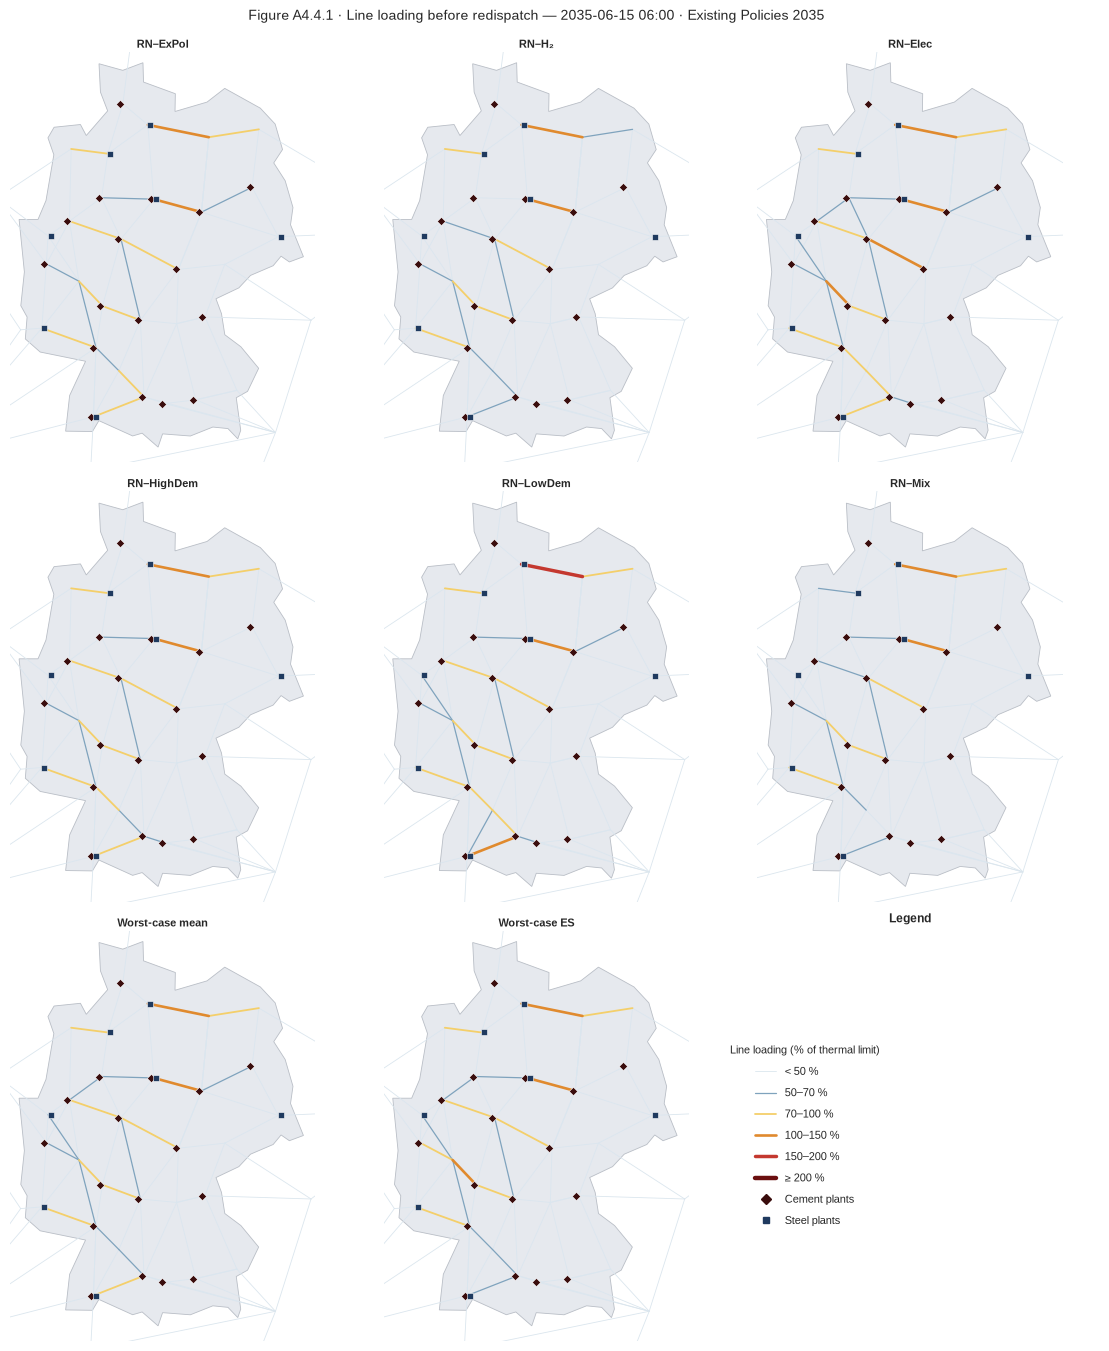

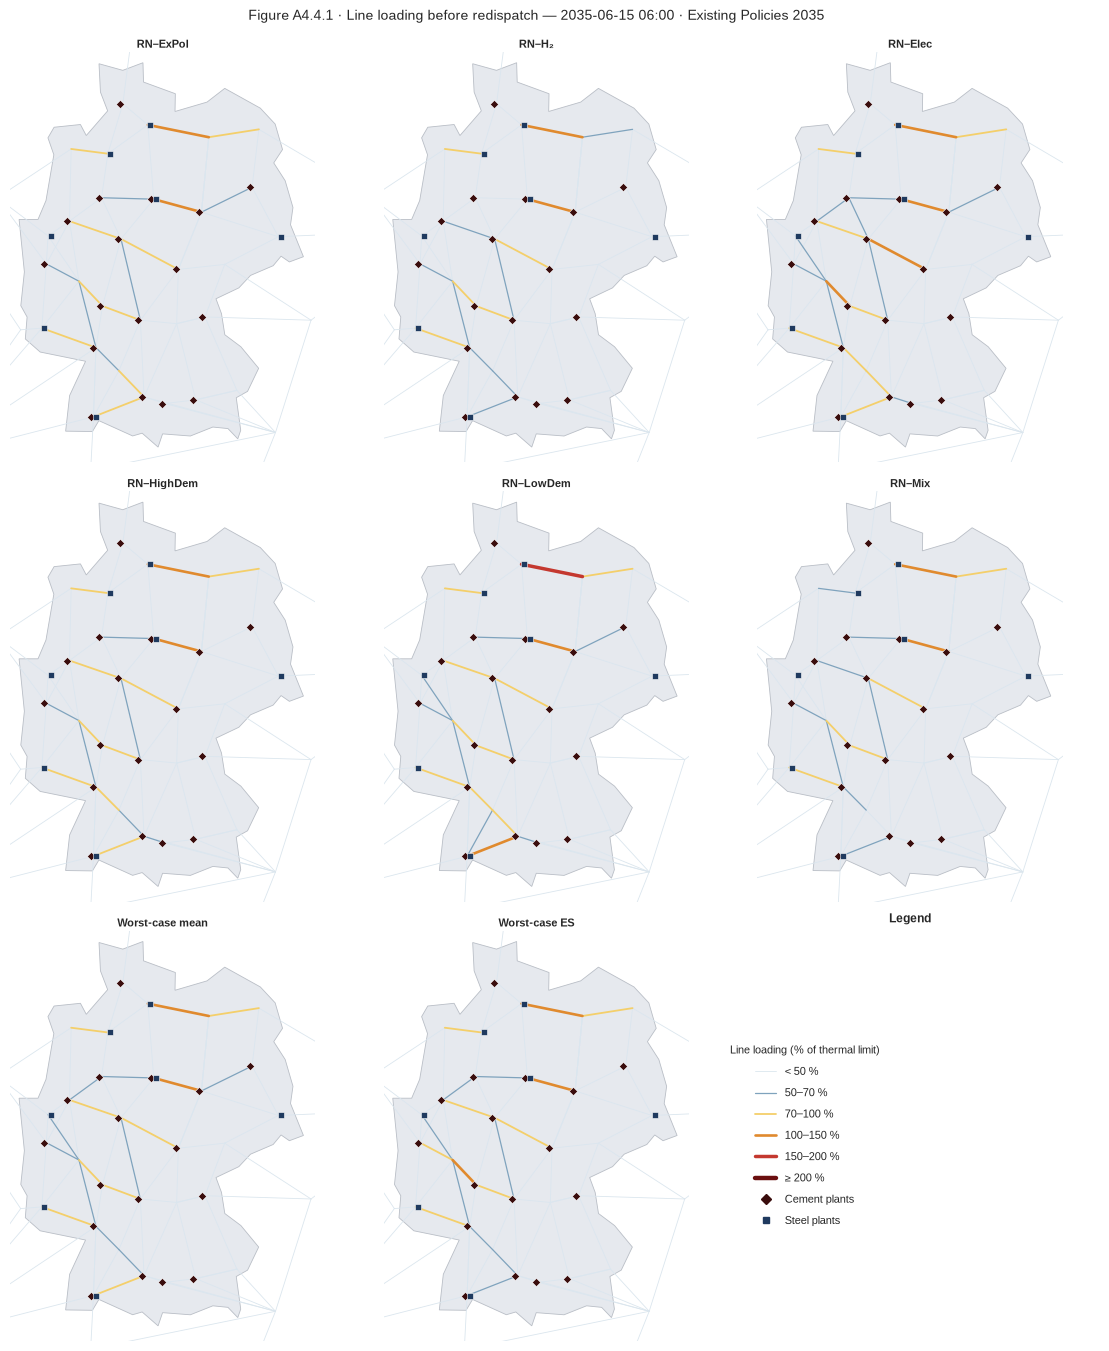

In [25]:
# Annex A4.4 — plotting helpers (styled to the §4.4 paper style)
shp = os.path.join(os.path.dirname(pyogrio.__file__),
                    "tests/fixtures/naturalearth_lowres/naturalearth_lowres.shp")
germany = gpd.read_file(shp).query("name == 'Germany'").geometry.iloc[0]

LOAD_BINS    = [0.5, 0.7, 1.005, 1.5, 2.0]
LOAD_LABELS  = ["< 50 %", "50–70 %", "70–100 %", "100–150 %", "150–200 %", "≥ 200 %"]
LOAD_COLORS  = ["#DBE6EE", "#7FA3BD", "#F4CF6A", "#E08A2E", "#C4382F", "#6B0F10"]
LOAD_WIDTHS  = [0.6, 0.9, 1.3, 1.9, 2.5, 3.2]
XLIM_DE, YLIM_DE = (5.7, 15.4), (47.0, 55.2)
UP_C, DOWN_C = "#2F77B5", "#D6604D"

def _base_map(ax, title):
    ax.add_patch(plt.Polygon(np.array(germany.exterior.coords),
                               fc="#E6E9EE", ec="#B9BEC6", lw=0.6, zorder=0))
    ax.set_xlim(*XLIM_DE); ax.set_ylim(*YLIM_DE)
    ax.set_aspect(1 / np.cos(np.radians(51)))
    ax.axis("off")
    ax.set_title(title, fontsize=8.2, fontweight="bold", pad=3)

def _draw_plants(ax, s):
    pos = s["buses"].set_index("name")[["x","y"]]
    for tech, marker, color, dx in [("cement","D","#3A0D0D",-0.08),
                                      ("steel", "s","#1F3A5F", 0.08)]:
        for node in s["plants"][tech]:
            ax.scatter(pos.loc[node,"x"] + dx, pos.loc[node,"y"],
                        marker=marker, s=18, c=color, ec="white", lw=0.4, zorder=6)

def _draw_loading(ax, s, key):
    pos = s["buses"].set_index("name")[["x","y"]]
    cls = np.digitize(s[key], LOAD_BINS)
    for i in np.argsort(cls):
        ln = s["lines"].iloc[i]
        a, b = pos.loc[ln.bus0], pos.loc[ln.bus1]
        ax.plot([a.x, b.x], [a.y, b.y], color=LOAD_COLORS[cls[i]],
                 lw=LOAD_WIDTHS[cls[i]], solid_capstyle="round", zorder=2+cls[i])
    _draw_plants(ax, s)

vmax_net = max(np.abs(s["net"]).max() for s in snaps.values())
def _bubble_area(v):
    return 35 + (abs(v) / vmax_net) * 650

def _draw_redispatch(ax, s):
    pos = s["buses"].set_index("name")[["x","y"]]
    for node, v in s["net"].items():
        if abs(v) >= 1:
            ax.scatter(pos.loc[node,"x"], pos.loc[node,"y"], s=_bubble_area(v),
                        c=UP_C if v > 0 else DOWN_C, alpha=0.85, ec="white", lw=0.4, zorder=4)
    _draw_plants(ax, s)

_plant_handles = [Line2D([],[], marker="D", ls="", c="#3A0D0D", ms=5, label="Cement plants"),
                   Line2D([],[], marker="s", ls="", c="#1F3A5F", ms=5, label="Steel plants")]
_load_handles  = ([Line2D([],[], color=c, lw=w, label=l)
                   for c,w,l in zip(LOAD_COLORS, LOAD_WIDTHS, LOAD_LABELS)]
                  + _plant_handles)
_size_steps = [g for g in (0.5, 1, 2, 4) if g*1000 <= vmax_net*1.05]
_rd_handles = ([Line2D([],[], marker="o", ls="", c=UP_C,   ms=8, label="Upward redispatch"),
                 Line2D([],[], marker="o", ls="", c=DOWN_C, ms=8, label="Downward redispatch")]
                + _plant_handles
                + [Line2D([],[], marker="o", ls="", mfc="none", mec="#444",
                           ms=np.sqrt(_bubble_area(g*1000)), label=f"{g:g} GW")
                   for g in _size_steps])

def _grid_fig(draw, handles, legend_title, suptitle, savename, note=None):
    fig, axes = plt.subplots(3, 3, figsize=(11.5, 13.5))
    for ax, c in zip(axes.flat, cases_g):
        _base_map(ax, aiu.case_label(c))
        draw(ax, snaps[c])
    for ax in list(axes.flat)[len(cases_g):]:
        ax.axis("off")
    leg = axes.flat[len(cases_g)]
    leg.set_title("Legend", fontsize=8.5, fontweight="bold")
    leg.legend(handles=handles, title=legend_title, loc="center left", frameon=False,
                fontsize=7.6, title_fontsize=8.0, labelspacing=1.05)
    if note:
        leg.text(0.02, 0.02, note, transform=leg.transAxes, fontsize=7.0, va="bottom", color="#333")
    fig.suptitle(suptitle, y=0.995, fontsize=10.2)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"{savename}.{ext}", bbox_inches="tight")
    plt.show()
    return fig

ts_label = f"{TS_ANNEX:%Y-%m-%d %H:%M} · {aiu.pathway_label(ANNEX_FAMILY, long=True)} {ANNEX_YEAR}"

# -------------------- Figure A4.4.1: PRE-redispatch line loading --------------------
_grid_fig(lambda ax, s: _draw_loading(ax, s, "pre"), _load_handles,
          "Line loading (% of thermal limit)",
          f"Figure A4.4.1 · Line loading before redispatch — {ts_label}",
          "figA441_lineload_pre")


**Figure A4.4.1 — reading.** Lines shown in orange / red / dark-red
are the overloaded 380 kV corridors at this hour. Across the eight cases
the overload geography is almost identical: a central north-to-south
corridor and one east-west tie-line stand out. The cases differ in the
*severity* (how many lines are > 100 %), not the *location*. This fixed
geography is why the annual upward redispatch volume (Fig 4.4a) sits in
such a tight 99–102 TWh band — the same corridors congest in essentially
every behavioural case, so the volume required to relieve them stays the
same to first order.


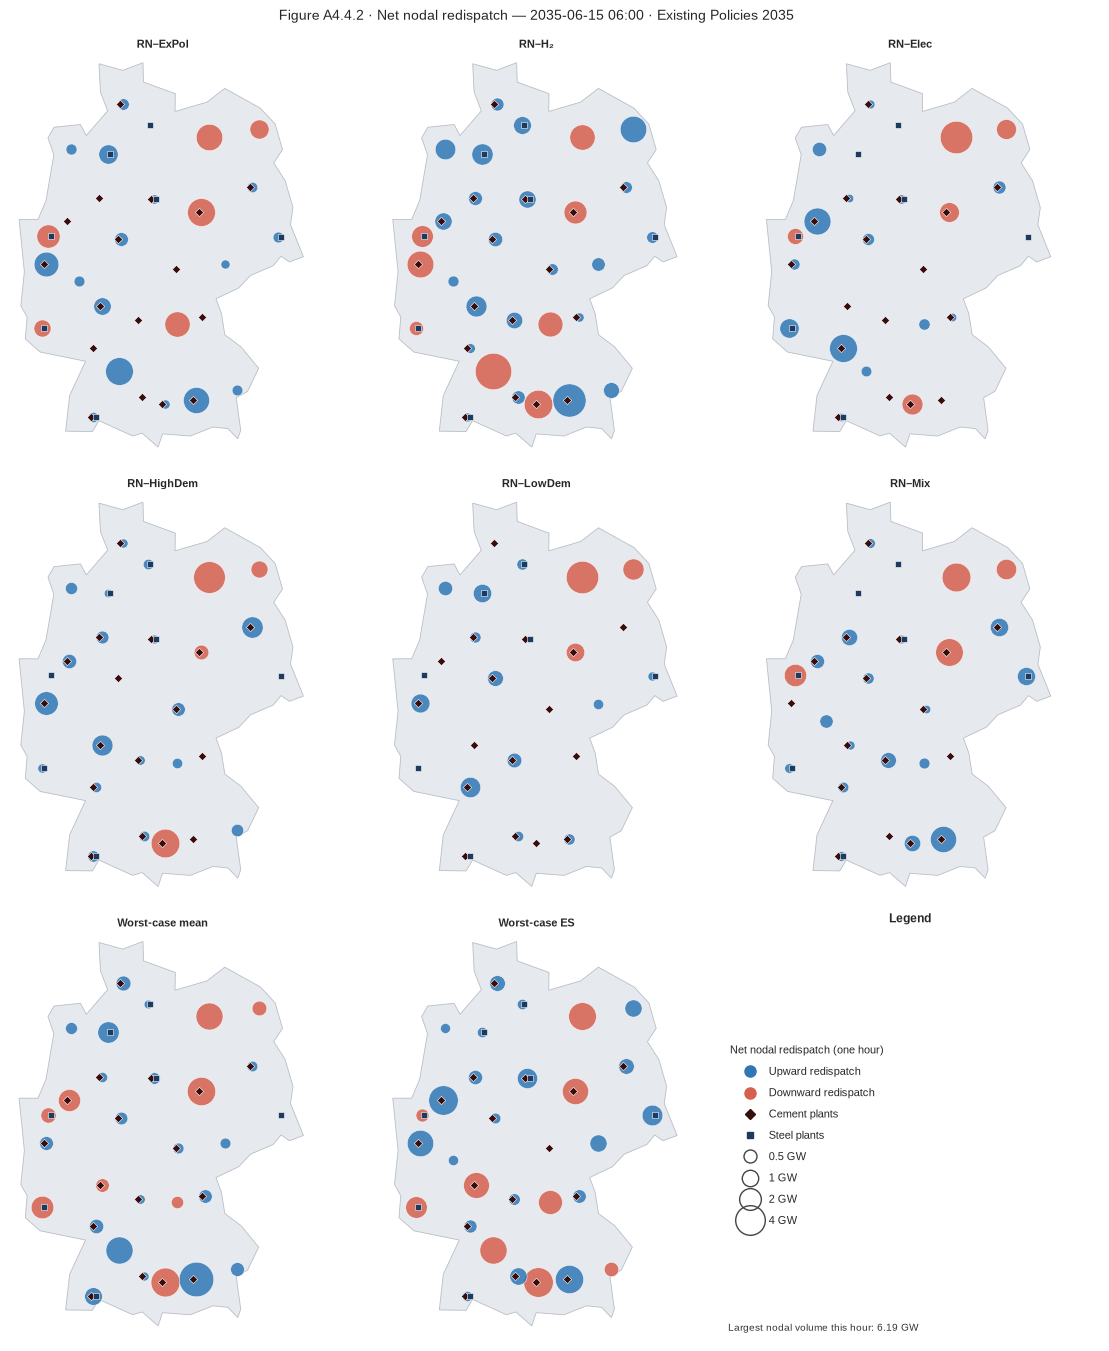

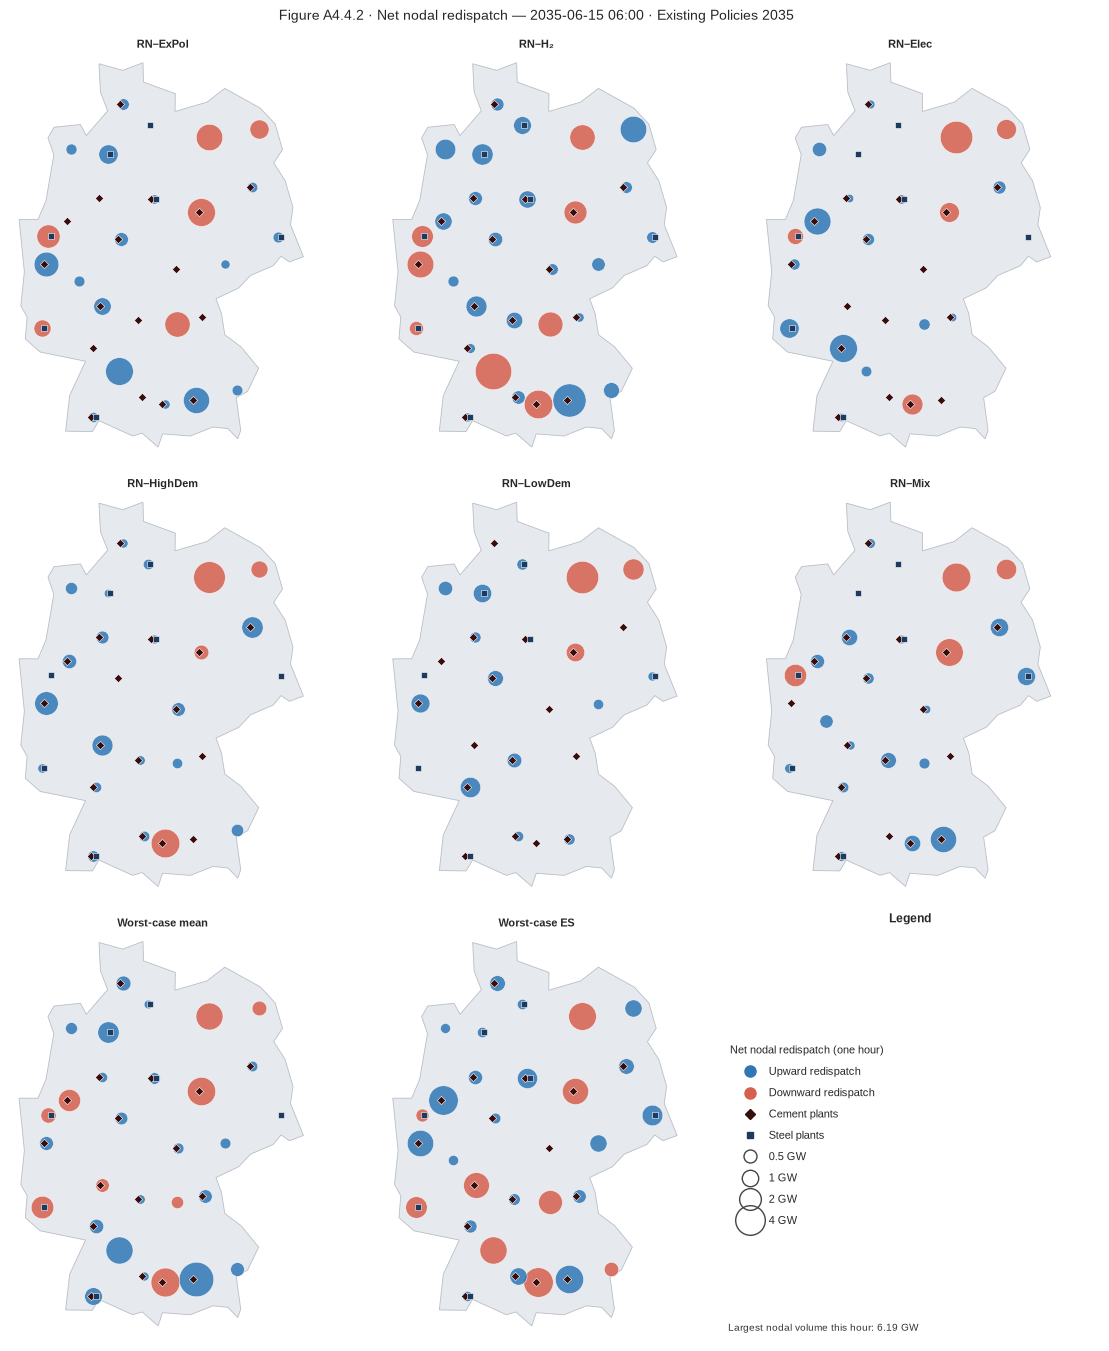

In [26]:
# -------------------- Figure A4.4.2: NET NODAL REDISPATCH --------------------
_grid_fig(_draw_redispatch, _rd_handles, "Net nodal redispatch (one hour)",
          f"Figure A4.4.2 · Net nodal redispatch — {ts_label}",
          "figA442_redispatch_bubbles",
          note=f"Largest nodal volume this hour: {vmax_net/1000:.2f} GW")


**Figure A4.4.2 — reading.** Blue bubbles (upward redispatch) concentrate
at central and southern DE nodes close to the conventional / industrial
load, especially the Ruhr corridor and the Munich–Stuttgart load axis
where the steel and cement plants sit (small squares and diamonds behind
the bubbles). Red bubbles (downward redispatch) cluster at coastal DE
nodes — Schleswig-Holstein, Niedersachsen, and the offshore-wind
connection points — exactly the north-to-south substitution that produces
the 70–80 TWh/y RES curtailment in Fig 4.4b.

At this specific hour (summer morning, 06:00), the total upward
redispatch *volume* across the cases ranges from ≈ 8 GW (RN–LowDem) to
≈ 24 GW (RN–H₂); see the hour-level table. The *number of nodes*
involved is similar across cases (12–22 up, 3–9 down), so the cases
differ mainly in *how much* each node has to shift rather than *which*
nodes they pick. Cement (diamonds) and steel (squares) markers
consistently fall on upward nodes: the new industrial demand pulls
generation up at its own bus and forces coastal RES down to maintain
the system balance — the physical origin of the wind + solar curtailment
ledger.

The annual cost ranking in Fig 4.4c / 4.4d (RN–HighDem / RN–LowDem /
RN–Mix at 8–9 EUR/MWh vs 4–6 EUR/MWh elsewhere) is driven by the
*locational marginal price at the southern upward nodes integrated over
the full year*, not by the GW volume at any single hour. At other hours
— for example windy winter nights — the sign pattern reverses (coastal
wind up-regulated, southern thermal curtailed) and the relative volumes
across cases shift again. What stays stable is that the high-
electrification cases pay a premium at their southern load buses
whenever those buses are the marginal upward node, which is what the
cost-weighted average price in Fig 4.4d (right axis) ultimately
records.


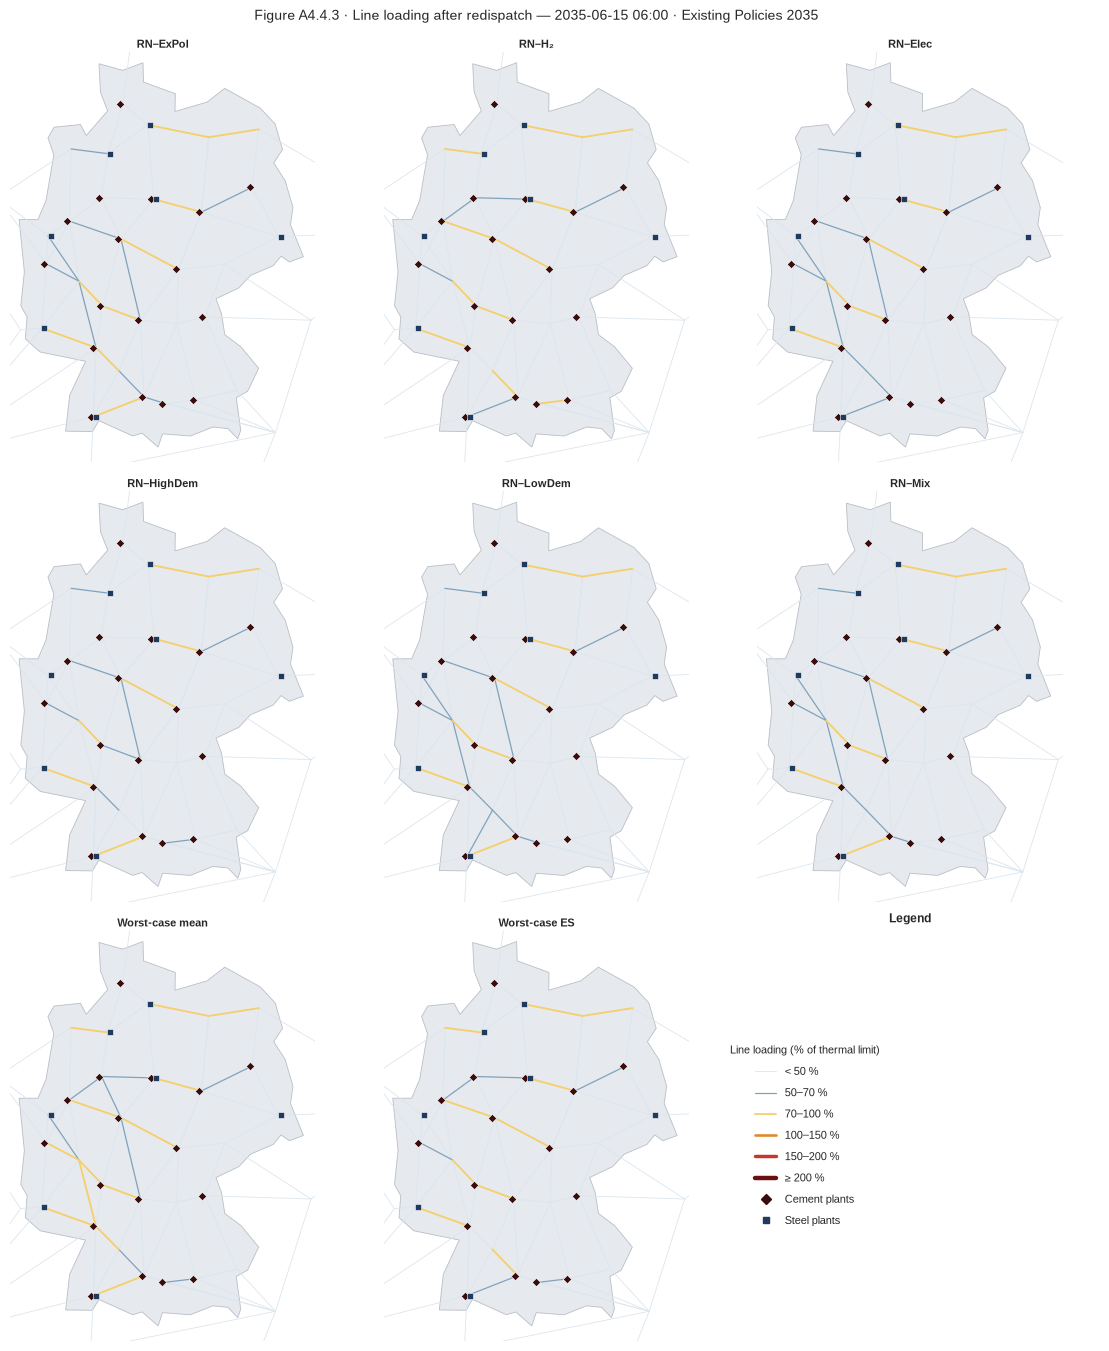

,lines > 100 % before,worst line before (%),lines > 100 % after,worst line after (%),upward redispatch (GW),downward redispatch (GW),nodes up / down
RN–ExPol,2,144,0,100,14.37,14.37,16 / 6
RN–H₂,2,124,0,100,23.51,23.51,22 / 8
RN–Elec,4,149,0,100,10.81,10.81,14 / 5
RN–HighDem,2,137,0,100,10.17,10.17,18 / 4
RN–LowDem,3,152,0,100,8.07,8.07,12 / 3
RN–Mix,2,133,0,100,10.97,10.97,17 / 4
Worst-case mean,2,138,0,100,17.46,17.46,19 / 9
Worst-case ES,3,134,0,100,22.38,22.38,20 / 9


In [27]:
# -------------------- Figure A4.4.3: POST-redispatch line loading --------------------
_grid_fig(lambda ax, s: _draw_loading(ax, s, "post"), _load_handles,
          "Line loading (% of thermal limit)",
          f"Figure A4.4.3 · Line loading after redispatch — {ts_label}",
          "figA443_lineload_post")

# -------------------- Hour-level summary table (same hour, all 8 cases) --------------------
annex_summary = pd.DataFrame({
    c: {
        "lines > 100 % before":  int((s["pre"]  > 1.005).sum()),
        "worst line before (%)": round(s["pre"].max()  * 100),
        "lines > 100 % after":   int((s["post"] > 1.005).sum()),
        "worst line after (%)":  round(s["post"].max() * 100),
        "upward redispatch (GW)": round(s["net"].clip(lower=0).sum() / 1000, 2),
        "downward redispatch (GW)": round(-s["net"].clip(upper=0).sum() / 1000, 2),
        "nodes up / down": f"{int((s['net'] > 1).sum())} / {int((s['net'] < -1).sum())}",
    } for c, s in snaps.items()
}).T
annex_summary.index = [aiu.case_label(c) for c in annex_summary.index]
annex_summary.to_csv(FIGDIR / "figA44_hour_summary.csv")
annex_summary


**Figure A4.4.3 — reading and connection to the main-text indicators.**

After redispatch, essentially every line is back below its thermal limit:
the yellow / orange bands (70–100 %) are the typical after state, and no
line sits above the 100 % band in any case at this hour. The PTDF-sign
validation in the setup cell confirms this across *every* congested hour
of one case — median worst-line after-loading ≈ 1.00 — so the three-panel
pre → redispatch → post story is physically consistent, not just picked
at one favourable hour.

**Connecting the mechanism to the annual numbers (§4.4).**

| Observation in the grid maps (this hour) | Annual counterpart in §4.4 |
|---|---|
| Same corridors congest in every case (Fig A4.4.1) | Upward redispatch volume is almost case-invariant: 99–102 TWh/y (Fig 4.4a, 4.4d left bars) |
| Coastal wind nodes supply the downward redispatch; steel / cement nodes receive upward (Fig A4.4.2) | Wind + solar curtailment ≈ 70–80 TWh/y; composition ~2 : 3 : 5 Wind-Offshore : Wind-Onshore : Solar PV, identical across cases (Fig 4.4b, 4.4d right panel) |
| Southern load-centre nodes are always the receiving (upward) end of the substitution (Fig A4.4.2) | Cost-weighted avg redispatch price splits cleanly: 8–9 EUR/MWh for RN–HighDem / RN–LowDem / RN–Mix vs 4–6 EUR/MWh elsewhere (Fig 4.4c, 4.4d line) |
| Post-redispatch loadings sit below 100 % everywhere (Fig A4.4.3) | Payments, not residual congestion, carry the case signal forward into §5 |

The three annex plots therefore translate the aggregate indicators into
the physical picture: a **structural north-to-south bottleneck** that
congests under every behavioural case (hence the tight volume band),
cured by a **coastal-RES ↓ / southern-thermal ↑ substitution** (hence
the curtailment–redispatch symmetry in Fig 4.4b vs 4.4a), with the
**cost per MWh set by the locational marginal price at the southern
load node**, which rises when the new industrial actors in
RN–HighDem / RN–LowDem / RN–Mix sit on top of that already-expensive
southern load (hence the payment doubling in Fig 4.4c).

**Scope and limits of the annex.**

- Only one pathway and one year are shown (**AktuellePolitiken 2035**,
  i.e. RN–ExPol). The three plots can be rebuilt for any other
  pathway / year by changing `ANNEX_FAMILY` and `ANNEX_YEAR` in the
  setup cell; `aiu.grid_snapshot(...)` caches the per-archive grid and
  redispatch data on first use.
- The hour is the one congested in the most cases with the largest
  combined overload (`2035-06-15 06:00`, congested in 8/8 cases).
  Other hours — a windy winter night, a solar-heavy summer midday —
  produce qualitatively similar maps (same corridors, opposite sign
  on the net bubbles) and are available by setting `TS_ANNEX` to a
  specific timestamp.
- The 30-bus zonal DE network means bubbles at a bus aggregate all
  units at that bus; sub-bus resolution of the redispatch pattern is
  not recoverable from the zonal model. The qualitative north-to-south
  story and the per-case ranking of the aggregate indicators are
  robust to this resolution limit.
